# cGAN Training

In [1]:
# Reproducibility
import random
import numpy as np
import torch

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
print(f"Random seed set to {SEED}")


Random seed set to 42


### Goal - To build and train our **conditional GAN (cGAN)** - a generative model that learsn to create **synthetic handwriting images** conditioned on digit labels

## Plan 

1. Understand the architecture of a **conditional Gan (cGAN)**
2. Implement **Generator** and **discriminator** in pytorch
3. Train model with adversarial objectives
4. Visualise class-conditional handwriting samples

## Recap (cGAN)

A **Generative Adversarial Network (GAN)** consists of:
- A **Generator (G)** that creates fake samples from random noise.
- A **Discriminator (D)** that tries to tell real from fake.

In a **Conditional GAN**, both G and D receive an **additional input**: a *class label*.  
This allows the model to generate specific digits or characters on demand.

In [2]:
# import core libraries
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision.utils import make_grid
import matplotlib.pyplot as plt
import numpy as np

import os, sys

from data_utils.dataloader import get_mnist_loaders
from model.cgan import Generator, Discriminator
from utils.visualize import show_batch
from utils.checkpoint import save_checkpoint

device = (
    "cuda" if torch.cuda.is_available() 
    else "mps" if torch.backends.mps.is_available() 
    else "cpu"
)
print(f" Running on device: {device}")

 Running on device: cuda


### Define Model Hyperparameters 


We’ll use a low-dimensional latent space (`z_dim = 100`),  
and condition the model on **10 digit classes (0–9)**.

GANs are notoriously sensitive to hyperparameters -  
we’ll start simple and iterate.

In [3]:
# hyperparameters 
z_dim = 100
num_classes = 10
img_shape = (1, 28, 28)
batch_size = 128
lr = 0.0002
epochs = 50

In [4]:
# Extract the MNIST data (images normalised to [-1, 1] by the loader)
train_loader, test_loader = get_mnist_loaders(
    batch_size=batch_size,
    num_workers=2,
    pin_memory=True,
)

print(f"Training batches: {len(train_loader)} | Test batches: {len(test_loader)}")


Training batches: 469 | Test batches: 79


Before we dive into training, let's define both our **Generator** and **Discriminator**.

Each will use the label embedding trick - where we turn the class label (e.g., “3”) into a learnable vector that can be concatenated with the noise or image input.

Our models are intentionally **lightweight** to make training on CPU/MPS feasible.  We’ll focus on the learning process and class conditioning rather than pixel-perfect realism.

In [5]:
# Instantiate the conditional GAN components
generator = Generator(z_dim=z_dim, num_classes=num_classes, img_shape=img_shape).to(device)
discriminator = Discriminator(num_classes=num_classes, img_shape=img_shape).to(device)

optimizer_G = optim.Adam(generator.parameters(), lr=lr, betas=(0.5, 0.999))
optimizer_D = optim.Adam(discriminator.parameters(), lr=lr, betas=(0.5, 0.999))
criterion = nn.BCELoss()

print(f"Generator parameters:     {sum(p.numel() for p in generator.parameters()):,}")
print(f"Discriminator parameters: {sum(p.numel() for p in discriminator.parameters()):,}")


Generator parameters:     1,498,448
Discriminator parameters: 2,263,051


## Training Strategy

We’ll alternate between training the **Discriminator (D)** and **Generator (G)**.

1. **Train D:**  
   - Use real images labeled as 1  
   - Use fake images (from G) labeled as 0  

2. **Train G:**  
   - Generate fake images  
   - Fool D into predicting them as 1  

This adversarial game continues until G generates *realistic*, class-conditioned digits.

In [6]:
# Train the cGAN: one Discriminator update then one Generator update per batch
from training.train_cgan import train_cgan

history = train_cgan(
    generator=generator,
    discriminator=discriminator,
    dataloader=train_loader,
    optimizer_G=optimizer_G,
    optimizer_D=optimizer_D,
    criterion=criterion,
    device=device,
    z_dim=z_dim,
    num_classes=num_classes,
    epochs=epochs,
)


[Epoch 1] D loss: 0.6529 | G loss: 0.8414
Saved checkpoint: C:\udacity\Deep-Learning\Udacity_Deep_Learning_P4_Synthetic_Handwriting_Generator\checkpoints\cgan_generator_epoch1.pt
Saved checkpoint: C:\udacity\Deep-Learning\Udacity_Deep_Learning_P4_Synthetic_Handwriting_Generator\checkpoints\cgan_discriminator_epoch1.pt
Saved checkpoint: C:\udacity\Deep-Learning\Udacity_Deep_Learning_P4_Synthetic_Handwriting_Generator\checkpoints\cgan_epoch_1.pt (and cgan_latest.pt)


[Epoch 2] D loss: 0.6480 | G loss: 0.8336
Saved checkpoint: C:\udacity\Deep-Learning\Udacity_Deep_Learning_P4_Synthetic_Handwriting_Generator\checkpoints\cgan_generator_epoch2.pt
Saved checkpoint: C:\udacity\Deep-Learning\Udacity_Deep_Learning_P4_Synthetic_Handwriting_Generator\checkpoints\cgan_discriminator_epoch2.pt
Saved checkpoint: C:\udacity\Deep-Learning\Udacity_Deep_Learning_P4_Synthetic_Handwriting_Generator\checkpoints\cgan_epoch_2.pt (and cgan_latest.pt)


[Epoch 3] D loss: 0.6476 | G loss: 0.8386
Saved checkpoint: C:\udacity\Deep-Learning\Udacity_Deep_Learning_P4_Synthetic_Handwriting_Generator\checkpoints\cgan_generator_epoch3.pt
Saved checkpoint: C:\udacity\Deep-Learning\Udacity_Deep_Learning_P4_Synthetic_Handwriting_Generator\checkpoints\cgan_discriminator_epoch3.pt
Saved checkpoint: C:\udacity\Deep-Learning\Udacity_Deep_Learning_P4_Synthetic_Handwriting_Generator\checkpoints\cgan_epoch_3.pt (and cgan_latest.pt)


[Epoch 4] D loss: 0.6402 | G loss: 0.8619
Saved checkpoint: C:\udacity\Deep-Learning\Udacity_Deep_Learning_P4_Synthetic_Handwriting_Generator\checkpoints\cgan_generator_epoch4.pt
Saved checkpoint: C:\udacity\Deep-Learning\Udacity_Deep_Learning_P4_Synthetic_Handwriting_Generator\checkpoints\cgan_discriminator_epoch4.pt
Saved checkpoint: C:\udacity\Deep-Learning\Udacity_Deep_Learning_P4_Synthetic_Handwriting_Generator\checkpoints\cgan_epoch_4.pt (and cgan_latest.pt)


[Epoch 5] D loss: 0.6479 | G loss: 0.8455
Saved checkpoint: C:\udacity\Deep-Learning\Udacity_Deep_Learning_P4_Synthetic_Handwriting_Generator\checkpoints\cgan_generator_epoch5.pt
Saved checkpoint: C:\udacity\Deep-Learning\Udacity_Deep_Learning_P4_Synthetic_Handwriting_Generator\checkpoints\cgan_discriminator_epoch5.pt
Saved checkpoint: C:\udacity\Deep-Learning\Udacity_Deep_Learning_P4_Synthetic_Handwriting_Generator\checkpoints\cgan_epoch_5.pt (and cgan_latest.pt)


[Epoch 6] D loss: 0.6584 | G loss: 0.8200
Saved checkpoint: C:\udacity\Deep-Learning\Udacity_Deep_Learning_P4_Synthetic_Handwriting_Generator\checkpoints\cgan_generator_epoch6.pt
Saved checkpoint: C:\udacity\Deep-Learning\Udacity_Deep_Learning_P4_Synthetic_Handwriting_Generator\checkpoints\cgan_discriminator_epoch6.pt
Saved checkpoint: C:\udacity\Deep-Learning\Udacity_Deep_Learning_P4_Synthetic_Handwriting_Generator\checkpoints\cgan_epoch_6.pt (and cgan_latest.pt)


... (40 outputs left out)

[Epoch 47] D loss: 0.6849 | G loss: 0.7331
Saved checkpoint: C:\udacity\Deep-Learning\Udacity_Deep_Learning_P4_Synthetic_Handwriting_Generator\checkpoints\cgan_generator_epoch47.pt
Saved checkpoint: C:\udacity\Deep-Learning\Udacity_Deep_Learning_P4_Synthetic_Handwriting_Generator\checkpoints\cgan_discriminator_epoch47.pt
Saved checkpoint: C:\udacity\Deep-Learning\Udacity_Deep_Learning_P4_Synthetic_Handwriting_Generator\checkpoints\cgan_epoch_47.pt (and cgan_latest.pt)


[Epoch 48] D loss: 0.6854 | G loss: 0.7292
Saved checkpoint: C:\udacity\Deep-Learning\Udacity_Deep_Learning_P4_Synthetic_Handwriting_Generator\checkpoints\cgan_generator_epoch48.pt
Saved checkpoint: C:\udacity\Deep-Learning\Udacity_Deep_Learning_P4_Synthetic_Handwriting_Generator\checkpoints\cgan_discriminator_epoch48.pt
Saved checkpoint: C:\udacity\Deep-Learning\Udacity_Deep_Learning_P4_Synthetic_Handwriting_Generator\checkpoints\cgan_epoch_48.pt (and cgan_latest.pt)


[Epoch 49] D loss: 0.6861 | G loss: 0.7272
Saved checkpoint: C:\udacity\Deep-Learning\Udacity_Deep_Learning_P4_Synthetic_Handwriting_Generator\checkpoints\cgan_generator_epoch49.pt
Saved checkpoint: C:\udacity\Deep-Learning\Udacity_Deep_Learning_P4_Synthetic_Handwriting_Generator\checkpoints\cgan_discriminator_epoch49.pt
Saved checkpoint: C:\udacity\Deep-Learning\Udacity_Deep_Learning_P4_Synthetic_Handwriting_Generator\checkpoints\cgan_epoch_49.pt (and cgan_latest.pt)


[Epoch 50] D loss: 0.6858 | G loss: 0.7274
Saved checkpoint: C:\udacity\Deep-Learning\Udacity_Deep_Learning_P4_Synthetic_Handwriting_Generator\checkpoints\cgan_generator_epoch50.pt
Saved checkpoint: C:\udacity\Deep-Learning\Udacity_Deep_Learning_P4_Synthetic_Handwriting_Generator\checkpoints\cgan_discriminator_epoch50.pt
Saved checkpoint: C:\udacity\Deep-Learning\Udacity_Deep_Learning_P4_Synthetic_Handwriting_Generator\checkpoints\cgan_epoch_50.pt (and cgan_latest.pt)


Saved checkpoint: ../checkpoints\cgan_generator_epochfinal.pt
Saved checkpoint: ../checkpoints\cgan_discriminator_epochfinal.pt


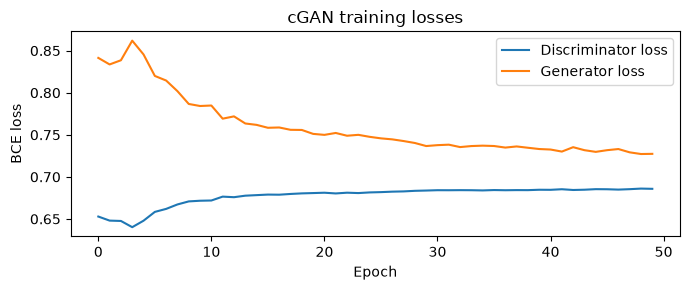

In [7]:
# Save the final generator and discriminator weights
save_checkpoint(generator, optimizer_G, epoch="final", name="cgan_generator")
save_checkpoint(discriminator, optimizer_D, epoch="final", name="cgan_discriminator")

# Training curves
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(history["d_loss"], label="Discriminator loss")
ax.plot(history["g_loss"], label="Generator loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("BCE loss")
ax.legend()
ax.set_title("cGAN training losses")
plt.tight_layout()
plt.show()


### Note
Training GANs can be unstable.  
If losses oscillate, that’s expected - D and G are in constant competition.

Let’s visualize a few generated samples at the end of training to check if conditioning worked.

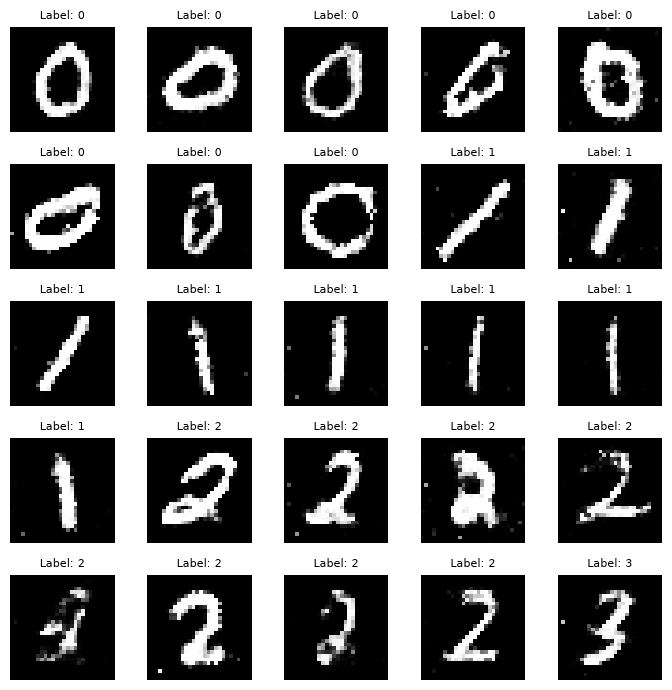

In [8]:
### Generate and visualize samples
def generate_samples(generator, n_classes=10, n_per_class=8):
    generator.eval()
    with torch.no_grad():
        z = torch.randn(n_classes * n_per_class, z_dim).to(device)
        labels = torch.tensor([i for i in range(n_classes) for _ in range(n_per_class)]).to(device)
        gen_imgs = generator(z, labels)
    generator.train()
    return gen_imgs, labels

gen_imgs, gen_labels = generate_samples(generator)
show_batch(gen_imgs.cpu(), gen_labels.cpu(), n=25)

We can now see grids of digits 0–9, each set showing several synthetic examples.  
Each class label corresponds to the digit the Generator was conditioned on.

Even if the images look a bit fuzzy, the model has learned the *concept* of conditioning -  
the generator “knows” which class to produce.

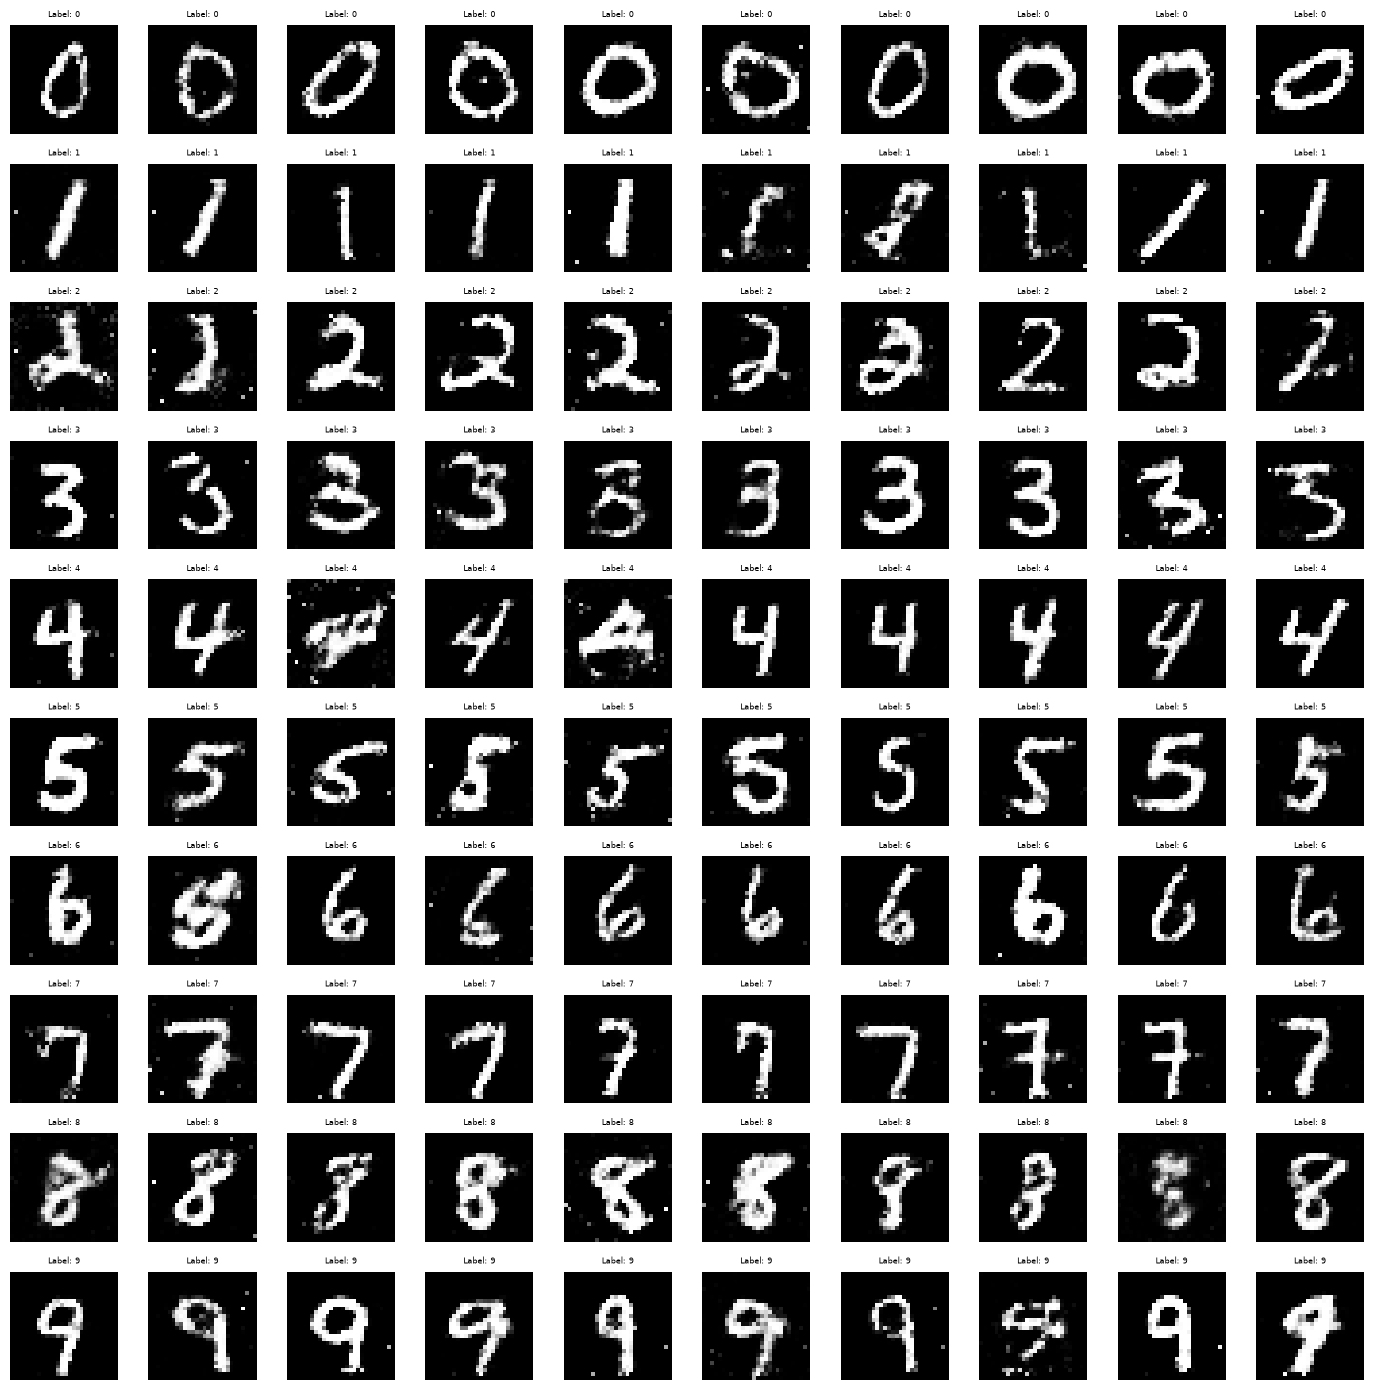

In [9]:
# Generate 10 samples per class (100 total) and display them
gen_imgs_100, gen_labels_100 = generate_samples(generator, n_classes=num_classes, n_per_class=10)
show_batch(gen_imgs_100.cpu(), gen_labels_100.cpu(), n=100)
